# NB11 · Assumptions, outputs and reporting

**Project:** multiyear-credit-engine
**Job requirement covered:** Build analytical frameworks that link assumptions, inputs and outputs; communicate to senior leaders.
**Engine module:** `creditengine.reporting`, `creditengine.simulation.portfolio`
**Assumptions:** All
**Theory:** Bluhm §5.2 (capital allocation)
**Status:** ✅ Developed — every function is built from scratch in this notebook

## Objective

What does the whole general-account credit book — bonds, commercial mortgages and structured tranches on one economy — lose and require in capital, which assumption drives each output, how does it behave in historical stresses, and what should each decision-maker take away?

## Results at a glance

| Question | Answer |
|---|---|
| What does the USD 1bn book lose in five years? | EL **10.8m** (1.08%); VaR 99.5% 76.6m; ES 99.5% **106.0m** — identical to the engine run in the README |
| How much does diversification save? | **9.8%** of economic capital versus the three asset classes held separately |
| Who uses the capital? | Corporates: 67% of exposure, 85% of EL, 67% of tail capital. **Structured: 16% of exposure, 2% of EL, 3% of RBC — but 25% of tail capital** |
| Do limits bind? | Against 70 / 15 / 15% of EC: structured **165%** (breach), corporates 96% (review), mortgages 55% |
| Which assumption matters most for the whole book? | Recoveries that fall in bad years (b = 0.25): ES **+64%**; cycle persistence 0.7: ES +39%; pool correlation 0.25: ES +27%. Statutory capital moves far less than ES |
| Historical stress | A 2000–04 replay: book EL ×2.2; severely adverse ×2.6; senior tranches untouched in every replay — they lose only in the model's deeper random tail |
| Is the summary traceable? | Every number in the executive summary is generated from computed values — checked automatically |

## How this notebook closes the loop

$$\text{assumptions} \;\rightarrow\; \text{one economy} \;\rightarrow\; \text{three asset engines} \;\rightarrow\; \text{one loss distribution} \;\rightarrow\; \text{capital, contributions, limits} \;\rightarrow\; \text{decisions}$$

| Section | Question |
|---|---|
| 1 | Is every assumption traceable from the register to the code that uses it? |
| 2 | What does the whole book lose and require, and who uses the capital? |
| 3 | Which assumption drives expected loss, tail loss and statutory capital? |
| 4 | What happens in historical and designed stresses? |
| 5 | What should ALM, the actuary, the investment team and the director take away? |

## Inputs

| Data | File | Used for |
|---|---|---|
| Matrix and thresholds (NB01, NB04) | `data/processed/` | bond and pool migration |
| NAIC factors, portfolio adjustment, rating map (NB01) | `data/external/` | statutory capital |
| Scenario paths (NB03) | `data/processed/scenarios.parquet` | stress section |
| Book settings | `configs/portfolios/*.yaml` (values declared in section 1) | the USD 1bn book |

## Outputs

- `reports/executive_summary.md` — one-page summary for four audiences, every number generated here
- `reports/figures/assumption_attribution.png` — which assumption moves which output
- `reports/figures/book_by_class.png` — exposure, expected loss and tail capital by asset class

## 0. Setup: three engines on one economy

$$G_t = \phi G_{t-1} + \sqrt{1-\phi^2} \eta_t, \qquad Z^{\text{bond}}_t = G_t, \qquad Z^{\text{CRE}}_t = \sqrt{\beta} G_t + \sqrt{1-\beta} H_t, \qquad Z^{\text{pool}}_t = G_t$$

One global credit cycle $G_t$ drives the bonds and the loan pool behind the structured tranches; the commercial real estate cycle is half global, half its own ($\beta$ = 0.5, A-14). Each asset class keeps its own engine (NB06, NB07, NB08); losses are stacked asset by asset so the book has one loss distribution.

In [1]:
from pathlib import Path
import re

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from scipy.stats import norm

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA, EXTERNAL, FIG = ROOT / "data", ROOT / "data" / "external", ROOT / "reports" / "figures"
RATINGS = ["AAA", "AA", "A", "BBB", "BB", "B", "CCC/C"]
STATES, D, Q = RATINGS + ["D"], 7, 0.995
pd.set_option("display.float_format", "{:,.2f}".format)

M = pd.read_parquet(DATA / "processed" / "transition_matrix_1y.parquet").loc[STATES, STATES]
C = pd.read_parquet(DATA / "processed" / "migration_thresholds.parquet").loc[STATES, STATES].to_numpy()
naic = pd.read_csv(EXTERNAL / "naic_bond_factors.csv", dtype={"naic_designation": str}).set_index("naic_designation")["factor_pct"] / 100
naic = naic.clip(upper=0.30)
scale = pd.read_csv(EXTERNAL / "rating_scale_map.csv", dtype=str).set_index("sp_category")
tiers = pd.read_csv(EXTERNAL / "naic_portfolio_adjustment.csv")
BOND_FACTOR = scale["naic_designation"].map(naic).reindex(STATES).to_numpy()

### 0.1 Assumption settings (the register, in code)

Every setting the notebook uses, with its register ID. Section 1 checks these against the register.

In [2]:
SET = {
    "A-01 matrix": "S&P 1981-2025, NR pro rata",          "A-02 bond rho": "Basel formula by rating",
    "A-03 phi": 0.50,                                      "A-04 bond LGD mean": 0.60, "A-04 bond LGD sd": 0.25,
    "A-04 pool LGD mean": 0.40, "A-04 pool LGD sd": 0.25,  "A-05 horizon (years)": 5,
    "A-06 capital multiple": 2.0, "A-06 cost of capital": 0.10,
    "A-07 value drift": 0.02, "A-07 value vol": 0.15, "A-07 value rho": 0.35,
    "A-07 NOI growth": 0.02, "A-07 NOI vol": 0.08, "A-07 NOI rho": 0.30,
    "A-07 selling cost": 0.25, "A-07 prepayment": 0.03, "A-07 refi rate": 0.06,
    "A-08 pool rho": 0.15, "A-09 book (USD)": 1.0e9, "A-13 LGD cycle b": 0.0, "A-14 beta CRE": 0.50,
    "A-15 held tranches (USD m)": "AAA 100, AA 40, A 20",
}
PATHS, SEED = 20_000, 2026
pd.Series(SET, name="value").to_frame()

,value
A-01 matrix,"S&P 1981-2025, NR pro rata"
A-02 bond rho,Basel formula by rating
A-03 phi,0.50
A-04 bond LGD mean,0.60
A-04 bond LGD sd,0.25
A-04 pool LGD mean,0.40
A-04 pool LGD sd,0.25
A-05 horizon (years),5
A-06 capital multiple,2.00
A-06 cost of capital,0.10


### 0.2 The three books (same as NB06, NB07, NB08; bonds scaled to USD 670m)

In [3]:
def bond_book(total=670e6, seed=7):
    mix = {"AAA": 0.03, "AA": 0.10, "A": 0.32, "BBB": 0.45, "BB": 0.06, "B": 0.03, "CCC/C": 0.01}
    mat = {"AAA": 8, "AA": 8, "A": 8, "BBB": 8, "BB": 6, "B": 6, "CCC/C": 4}
    rng = np.random.default_rng(seed)
    w = np.array([mix[r] for r in RATINGS])
    rating = np.repeat(np.arange(7), np.round(w * 200).astype(int))
    size = rng.lognormal(0.0, 0.5, rating.size)
    exp = np.zeros(rating.size)
    for r in range(7):
        m = rating == r
        exp[m] = size[m] / size[m].sum() * w[r] * total
    maturity = rng.integers(1, 2 * np.array([mat[RATINGS[r]] for r in rating]), endpoint=True)
    wt = (1 - np.exp(-50 * M.to_numpy()[rating, D])) / (1 - np.exp(-50))
    return pd.DataFrame({"rating": rating, "exposure": exp, "maturity": maturity, "rho": 0.12 * wt + 0.24 * (1 - wt)})

def annual_payment(b, r, n):
    return b * r / (1 - (1 + r) ** (-n))

def balance_after(b, r, n, t):
    g = (1 + r) ** t
    return b * g - annual_payment(b, r, n) * (g - 1) / r

def cre_book(seed=11):
    mix = {"apartment": 0.42, "industrial": 0.22, "retail": 0.22, "office": 0.12, "hotel": 0.02}
    rng = np.random.default_rng(seed)
    types = np.repeat(list(mix), np.round(np.array(list(mix.values())) * 60).astype(int))
    size = rng.lognormal(0.0, 0.6, types.size)
    bal = np.zeros(types.size)
    for k, s in mix.items():
        m = types == k
        bal[m] = size[m] / size[m].sum() * s * 170e6
    office = types == "office"
    ltv = np.clip(rng.normal(0.60, 0.12, types.size) + office * 0.12, 0.30, 0.95)
    dscr = np.clip(rng.normal(2.0, 0.45, types.size) - office * 0.45, 1.10, 3.50)
    ds = annual_payment(bal, 0.05, 25)
    return pd.DataFrame({"type": types, "balance": bal, "value": bal / ltv, "noi": dscr * ds, "debt_service": ds,
                         "maturity": rng.integers(1, 10, endpoint=True, size=types.size)})

TRANCHES = pd.DataFrame([("equity", 0.00, 0.13, "6"), ("BB", 0.13, 0.17, "3.B"), ("BBB", 0.17, 0.21, "2.B"),
                         ("A", 0.21, 0.25, "1.F"), ("AA", 0.25, 0.30, "1.C"), ("AAA", 0.30, 1.00, "1.A")],
                        columns=["name", "attach", "detach", "designation"]).set_index("name")
HELD = {"AAA": 100e6, "AA": 40e6, "A": 20e6}
POOL_RATING = np.repeat([RATINGS.index("BB"), RATINGS.index("B"), RATINGS.index("CCC/C")], [60, 130, 10])

bonds, cre = bond_book(), cre_book()
pd.DataFrame({"assets": [len(bonds), len(cre), len(HELD)],
              "exposure, USD m": [bonds["exposure"].sum() / 1e6, cre["balance"].sum() / 1e6, sum(HELD.values()) / 1e6]},
             index=["corporate bonds", "commercial mortgages", "structured (held tranches)"])

,assets,"exposure, USD m"
corporate bonds,200,670.00
commercial mortgages,59,170.00
structured (held tranches),3,160.00


### 0.3 Engines

In [4]:
def cycle_paths(n, years, phi, rng):
    z, prev = np.empty((n, years)), rng.standard_normal(n)
    for t in range(years):
        z[:, t] = phi * prev + np.sqrt(1 - phi**2) * rng.standard_normal(n)
        prev = z[:, t]
    return z

def migrate(state, A):
    new = state.copy()
    for r in range(7):
        m = state == r
        new[m] = 7 - np.searchsorted(C[r, 7:0:-1], A[m], side="left")
    return new

def lgd_draw(mean, sd, rng, shape=None):
    mean = np.clip(np.asarray(mean, dtype=float), 1e-4, 1 - 1e-4)
    var = np.minimum(sd**2, 0.81 * mean * (1 - mean))
    k = mean * (1 - mean) / var - 1
    return rng.beta(mean * k, (1 - mean) * k, size=shape)

def rated_engine(rating, ead, mat, rho, z, lgd_mean, lgd_sd, b, seed):
    # NB06 engine on a supplied factor path; returns per-asset loss by year and rating paths
    rng = np.random.default_rng(seed)
    n_paths, years = z.shape
    state = np.tile(rating, (n_paths, 1))
    ratings = np.empty((n_paths, years + 1, len(rating)), np.int8)
    ratings[:, 0] = state
    loss = np.zeros((n_paths, years, len(rating)))
    for t in range(years):
        alive = (state != D) & (mat[None, :] > t)
        A = np.sqrt(rho) * z[:, t:t + 1] + np.sqrt(1 - rho) * rng.standard_normal(state.shape)
        new = np.where(alive, migrate(state, A), state)
        if b == 0:
            lgd = lgd_draw(lgd_mean, lgd_sd, rng, shape=state.shape)
        else:
            a_ = norm.ppf(lgd_mean) * np.sqrt(1 + b**2)                    # cycle-linked mean LGD (NB05)
            lgd = lgd_draw(np.broadcast_to(norm.cdf(a_ - b * z[:, t:t + 1]), state.shape), lgd_sd, rng)
        loss[:, t] = (alive & (new == D)) * ead * lgd
        state = new
        ratings[:, t + 1] = state
    return loss, ratings

In [5]:
GRID = pd.DataFrame([(4, 1, 1.50, np.inf, 0, .85), (4, 2, 0, 1.50, 0, .55), (4, 2, .95, 1.50, .55, .75), (4, 2, 1.15, 1.50, .75, 1),
                     (4, 2, 1.50, np.inf, .85, 1), (4, 2, 1.75, np.inf, 1, np.inf), (4, 3, 0, .95, .55, .85), (4, 3, .95, 1.15, .75, 1),
                     (4, 3, 1.15, 1.75, 1, np.inf), (4, 4, 0, .95, .85, 1.05), (4, 4, .95, 1.15, 1, np.inf), (4, 5, 0, .95, 1.05, np.inf),
                     (5, 1, 1.85, np.inf, 0, .60), (5, 2, 1.45, 1.85, 0, .70), (5, 2, 1.85, np.inf, .60, 1.15), (5, 3, .90, 1.45, 0, .80),
                     (5, 3, 1.45, 1.85, .70, np.inf), (5, 3, 1.85, np.inf, 1.15, np.inf), (5, 4, 0, .90, 0, .90), (5, 4, .90, 1.10, .80, .90),
                     (5, 4, 1.10, 1.45, .80, np.inf), (5, 5, 0, 1.10, .90, np.inf)],
                    columns=["figure", "cm", "d0", "d1", "l0", "l1"])                    # NAIC Figures 4 and 5 (NB07)
CM_FACTOR = np.array([0, 0.0090, 0.0175, 0.0300, 0.0500, 0.0750])

def cm_category(dscr, ltv, hotel):
    cat = np.zeros(dscr.shape, np.int8)
    for r in GRID.itertuples():
        inside = (dscr >= r.d0) & (dscr < r.d1) & (ltv >= r.l0) & (ltv < r.l1)
        cat[inside & (hotel == (r.figure == 5))] = r.cm
    return cat

def cre_engine(book, z, s, seed=7):
    # NB07 engine on a supplied CRE factor path; per-loan loss by year and RBC path
    rng = np.random.default_rng(seed)
    n_paths, years = z.shape
    log_v = np.tile(np.log(book["value"].to_numpy()), (n_paths, 1))
    log_n = np.tile(np.log(book["noi"].to_numpy()), (n_paths, 1))
    ds, mat, b0 = book["debt_service"].to_numpy(), book["maturity"].to_numpy(), book["balance"].to_numpy()
    hotel = (book["type"] == "hotel").to_numpy()
    alive = np.ones((n_paths, len(book)), bool)
    loss = np.zeros((n_paths, years, len(book)))
    rbc = np.zeros((n_paths, years + 1))
    rbc[:, 0] = (CM_FACTOR[cm_category(book["noi"].to_numpy() / ds, b0 / book["value"].to_numpy(), hotel)] * b0).sum()
    for t in range(1, years + 1):
        zt = z[:, t - 1:t]
        log_v += s["value_drift"] - 0.5 * s["value_vol"]**2 + s["value_vol"] * (np.sqrt(s["value_rho"]) * zt + np.sqrt(1 - s["value_rho"]) * rng.standard_normal(log_v.shape))
        log_n += s["noi_growth"] - 0.5 * s["noi_vol"]**2 + s["noi_vol"] * (np.sqrt(s["noi_rho"]) * zt + np.sqrt(1 - s["noi_rho"]) * rng.standard_normal(log_n.shape))
        value, noi = np.exp(log_v), np.exp(log_n)
        bal = balance_after(b0, 0.05, 25, t)[None, :]
        dscr, ltv = noi / ds, bal / value
        term = (dscr < 1) & (ltv > 1)
        balloon = (mat == t) & ((ltv > 1) | (noi / annual_payment(bal, s["refi_rate"], 25) < 1))
        default = alive & (term | balloon)
        loss[:, t - 1] = np.where(default, np.maximum(bal - (1 - s["selling_cost"]) * value, 0), 0)
        prepaid = alive & ~default & (rng.random(alive.shape) < s["prepay_rate"])
        alive &= ~(default | prepaid | (mat == t))
        rbc[:, t] = (np.where(alive, CM_FACTOR[cm_category(dscr, ltv, np.broadcast_to(hotel, dscr.shape))] * bal, 0)).sum(axis=1)
    return loss, rbc

def portfolio_adjustment(n):
    n = np.asarray(n, dtype=float)
    sizes = tiers["issuers_in_tier"].fillna(np.inf).to_numpy()
    lower = np.r_[0.0, np.cumsum(sizes[:-1])]
    return np.divide((np.clip(n[..., None] - lower, 0, sizes) * tiers["factor"].to_numpy()).sum(-1), n, out=np.zeros_like(n), where=n > 0)

### 0.4 The whole book

One call: draw the global cycle, build the CRE and pool factors, run the three engines, stack the losses. Settings can be overridden for the attribution and stress sections.

In [6]:
CRE_SET = {"value_drift": 0.02, "value_vol": 0.15, "value_rho": 0.35, "noi_growth": 0.02, "noi_vol": 0.08, "noi_rho": 0.30,
           "selling_cost": 0.25, "prepay_rate": 0.03, "refi_rate": 0.06}

def run_book(paths=PATHS, seed=SEED, phi=0.5, beta_cre=0.5, bond_rho_scale=1.0, bond_lgd=0.60, b=0.0, pool_rho=0.15,
             cre_over=None, global_path=None):
    rng = np.random.default_rng(seed)
    g = cycle_paths(paths, 5, phi, rng) if global_path is None else np.tile(np.asarray(global_path, float), (paths, 1))
    z_cre = g if beta_cre >= 1 else np.sqrt(beta_cre) * g + np.sqrt(1 - beta_cre) * cycle_paths(paths, 5, phi, rng)
    bl, br = rated_engine(bonds["rating"].to_numpy(), bonds["exposure"].to_numpy(), bonds["maturity"].to_numpy(),
                          np.clip(bonds["rho"].to_numpy() * bond_rho_scale, 0, 0.99), g, bond_lgd, 0.25, b, seed + 1)
    cl, crbc = cre_engine(cre, z_cre, {**CRE_SET, **(cre_over or {})})
    pl, _ = rated_engine(POOL_RATING, np.ones(200), np.full(200, 7), pool_rho, g, 0.40, 0.25, b, seed + 3)
    pool_cum = np.cumsum(pl.sum(axis=2), axis=1) / 200                                  # (paths, years)
    tr_loss, tr_year, tr_rbc = [], np.zeros((paths, 5)), np.zeros((paths, 6))
    for name, held in HELD.items():
        r = TRANCHES.loc[name]
        cum = (np.maximum(pool_cum - r.attach, 0) - np.maximum(pool_cum - r.detach, 0)) / (r.detach - r.attach)
        cum0 = np.hstack([np.zeros((paths, 1)), cum])
        tr_year += held * np.diff(cum0, axis=1)
        tr_loss.append(held * cum[:, -1])
        tr_rbc += held * (1 - cum0) * naic[r.designation]
    live = lambda t: (br[:, t] != D) & (bonds["maturity"].to_numpy()[None, :] > t)
    b_rbc = np.stack([(BOND_FACTOR[br[:, t]] * bonds["exposure"].to_numpy() * live(t)).sum(1) * portfolio_adjustment(live(t).sum(1))
                      for t in range(6)], axis=1)
    asset_loss = np.hstack([bl.sum(axis=1), cl.sum(axis=1), np.column_stack(tr_loss)])
    return {"asset_loss": asset_loss, "by_class": {"corporate bonds": bl.sum(axis=(1, 2)), "commercial mortgages": cl.sum(axis=(1, 2)),
                                                   "structured": tr_year.sum(axis=1)},
            "rbc": {"corporate bonds": b_rbc, "commercial mortgages": crbc, "structured": tr_rbc}}

CLASS = np.array(["corporate bonds"] * len(bonds) + ["commercial mortgages"] * len(cre) + ["structured"] * len(HELD))
GROUP = np.array(list(np.array(RATINGS)[bonds["rating"]]) + list(cre["type"]) + [f"tranche {k}" for k in HELD])
EXPOSURE = np.r_[bonds["exposure"], cre["balance"], list(HELD.values())]
book = run_book()
print("whole book simulated:", book["asset_loss"].shape)

whole book simulated: (20000, 262)


## 1. Assumption register to configuration traceability

Each assumption ID, where its value lives, which notebook sets or tests it, and how much it moves the tail (NB10 tornado and NB05). The check: the values used in this notebook are the register values.

In [7]:
register = pd.DataFrame([
    ("A-01", "One-year transition matrix", "S&P 1981-2025, NR pro rata", "data/external/transition_matrix_1y.csv", "NB01, NB04", "P^n overstates B 5-yr default (NB10 V-03)"),
    ("A-02", "Asset correlation", "Basel formula by rating", "configs/base.yaml", "NB03, NB06", "rho x0.75 / x1.25: ES -20% / +23%"),
    ("A-03", "Cycle persistence phi", 0.50, "configs/base.yaml", "NB03", "phi 0 / 0.7: ES -36% / +32%"),
    ("A-04", "LGD bonds / pool loans", "60% / 40%, sd 25%", "configs/base.yaml, structured.yaml", "NB05", "LGD 50% / 70%: ES -15% / +21%"),
    ("A-05", "Horizon, static book", "5 years", "configs/base.yaml", "NB06", "-"),
    ("A-06", "RBC factors, capital multiple, CoC", "Academy 2021; 2x; 10%", "data/external/naic_*.csv", "NB01, NB09", "break-even spreads"),
    ("A-07", "Property value and NOI", "vol 15% / 8%, kappa 25%, refi 6%", "commercial_mortgages.yaml", "NB07", "section 3 below"),
    ("A-08", "Structured pool", "200 loans, rho 0.15", "structured.yaml", "NB08", "pool rho 25%: A tranche EL x3.7"),
    ("A-09", "Stylised book", "USD 1bn: 67 / 17 / 16%", "insurer_book.yaml", "NB11", "-"),
    ("A-10", "Copula", "Gaussian (t as challenger)", "engine option", "NB06, NB10", "t copula: ES +66%"),
    ("A-11", "Sector factors", "one global factor", "engine option", "NB06, NB10", "beta 0.5: ES -34%"),
    ("A-13", "LGD linked to cycle", "b = 0 (challenger 1)", "configs/base.yaml", "NB05", "b = 1: ES +67%"),
    ("A-14", "CRE link to global cycle", "beta = 0.5", "insurer_book.yaml", "NB07, NB11", "section 3 below"),
    ("A-15", "Held tranches, designation", "AAA 100, AA 40, A 20; fixed", "structured.yaml", "NB08", "A tranche: 70% of stack tail capital"),
], columns=["ID", "assumption", "value", "set in", "set / tested in", "sensitivity"]).set_index("ID")

used = {"A-03": SET["A-03 phi"] == 0.50, "A-04": (SET["A-04 bond LGD mean"], SET["A-04 pool LGD mean"]) == (0.60, 0.40),
        "A-07": (CRE_SET["value_vol"], CRE_SET["noi_vol"], CRE_SET["selling_cost"], CRE_SET["refi_rate"]) == (0.15, 0.08, 0.25, 0.06),
        "A-08": SET["A-08 pool rho"] == 0.15, "A-09": abs(EXPOSURE.sum() - 1e9) < 1, "A-13": SET["A-13 LGD cycle b"] == 0.0,
        "A-14": SET["A-14 beta CRE"] == 0.50, "A-15": HELD == {"AAA": 100e6, "AA": 40e6, "A": 20e6}}
register["value in this notebook matches"] = pd.Series(used).map({True: "yes", False: "NO"})
register.fillna("-")

,assumption,value,set in,set / tested in,sensitivity,value in this notebook matches
ID,,,,,,
A-01,One-year transition matrix,"S&P 1981-2025, NR pro rata",data/external/transition_matrix_1y.csv,"NB01, NB04",P^n overstates B 5-yr default (NB10 V-03),-
A-02,Asset correlation,Basel formula by rating,configs/base.yaml,"NB03, NB06",rho x0.75 / x1.25: ES -20% / +23%,-
A-03,Cycle persistence phi,0.50,configs/base.yaml,NB03,phi 0 / 0.7: ES -36% / +32%,yes
A-04,LGD bonds / pool loans,"60% / 40%, sd 25%","configs/base.yaml, structured.yaml",NB05,LGD 50% / 70%: ES -15% / +21%,yes
A-05,"Horizon, static book",5 years,configs/base.yaml,NB06,-,-
A-06,"RBC factors, capital multiple, CoC",Academy 2021; 2x; 10%,data/external/naic_*.csv,"NB01, NB09",break-even spreads,-
A-07,Property value and NOI,"vol 15% / 8%, kappa 25%, refi 6%",commercial_mortgages.yaml,NB07,section 3 below,yes
A-08,Structured pool,"200 loans, rho 0.15",structured.yaml,NB08,pool rho 25%: A tranche EL x3.7,yes
A-09,Stylised book,USD 1bn: 67 / 17 / 16%,insurer_book.yaml,NB11,-,yes


## 2. The whole book: losses, diversification, contributions and capital

$$\text{diversification} = 1 - \frac{EC_{\text{book}}}{\sum_{\text{classes}} EC_{\text{class}}}, \qquad EC = ES_q - EL, \quad q = 0.995$$

How much less capital the book needs than its three parts held separately, because they do not all have their worst year at once.

In [8]:
def loss_stats(L):
    var = np.quantile(L, Q)
    es = L[L >= var].mean()
    return {"EL": L.mean() / 1e6, "VaR 99.5%": var / 1e6, "ES 99.5%": es / 1e6, "EC (ES - EL)": (es - L.mean()) / 1e6}

L_book = book["asset_loss"].sum(axis=1)
summary = pd.DataFrame({k: loss_stats(v) for k, v in book["by_class"].items()})
summary["whole book"] = pd.Series(loss_stats(L_book))
diversification = 1 - summary.loc["EC (ES - EL)", "whole book"] / summary.loc["EC (ES - EL)", list(book["by_class"])].sum()
print(f"diversification benefit: {diversification:.1%}   (USD m below)")
summary

diversification benefit: 9.8%   (USD m below)


,corporate bonds,commercial mortgages,structured,whole book
EL,9.16,1.47,0.17,10.80
VaR 99.5%,59.05,13.16,12.98,76.62
ES 99.5%,74.84,16.14,25.34,106.02
EC (ES - EL),65.68,14.66,25.17,95.22


In [9]:
var_b = np.quantile(L_book, Q)
tail = L_book >= var_b
rc = book["asset_loss"][tail].mean(axis=0) - book["asset_loss"].mean(axis=0)

def contributions(by):
    g = pd.DataFrame({"by": by, "exposure": EXPOSURE, "EL": book["asset_loss"].mean(axis=0), "RC": rc}).groupby("by", sort=False).sum()
    return pd.DataFrame({"exposure %": 100 * g["exposure"] / g["exposure"].sum(), "EL %": 100 * g["EL"] / g["EL"].sum(),
                         "ES capital %": 100 * g["RC"] / g["RC"].sum(), "EC per 100": 100 * g["RC"] / g["exposure"]})

by_class = contributions(CLASS)
rbc = pd.DataFrame({k: {"year 0": v[0, 0] / 1e6, "year 5 median": np.median(v[:, -1]) / 1e6, "year 5 p99.5": np.percentile(v[:, -1], 99.5) / 1e6}
                    for k, v in book["rbc"].items()}).T
total_rbc = sum(book["rbc"].values())
rbc.loc["whole book"] = [total_rbc[0, 0] / 1e6, np.median(total_rbc[:, -1]) / 1e6, np.percentile(total_rbc[:, -1], 99.5) / 1e6]
by_class.join(rbc, how="left")

,exposure %,EL %,ES capital %,EC per 100,year 0,year 5 median,year 5 p99.5
by,,,,,,,
corporate bonds,67.00,84.80,66.97,9.52,20.32,17.73,35.30
commercial mortgages,17.00,13.64,8.31,4.66,1.91,0.74,1.77
structured,16.00,1.56,24.72,14.71,0.71,0.71,0.71


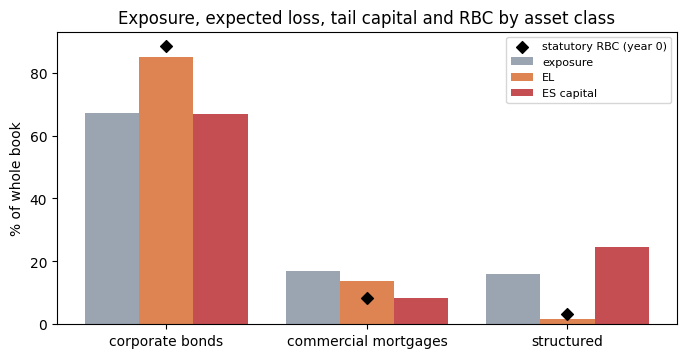

In [10]:
fig, ax = plt.subplots(figsize=(8, 3.8))
x = np.arange(len(by_class))
for i, (col, c) in enumerate([("exposure %", "#9AA5B1"), ("EL %", "#DD8452"), ("ES capital %", "#C44E52")]):
    ax.bar(x + (i - 1) * 0.27, by_class[col], 0.27, color=c, label=col.replace(" %", ""))
rbc_share = 100 * rbc.loc[by_class.index, "year 0"] / rbc.loc[by_class.index, "year 0"].sum()
ax.scatter(x, rbc_share, color="black", zorder=3, marker="D", label="statutory RBC (year 0)")
ax.set_xticks(x, by_class.index)
ax.set(ylabel="% of whole book", title="Exposure, expected loss, tail capital and RBC by asset class")
ax.legend(fontsize=8)
fig.savefig(FIG / "book_by_class.png", dpi=150, bbox_inches="tight")
plt.show()

In [11]:
LIMITS = pd.Series({"corporate bonds": 0.70, "commercial mortgages": 0.15, "structured": 0.15})
ec_book = summary.loc["EC (ES - EL)", "whole book"]
util = pd.DataFrame({"ES capital, USD m": pd.Series(rc).groupby(CLASS).sum() / 1e6, "limit, USD m": LIMITS * ec_book})
util["utilisation %"] = 100 * util["ES capital, USD m"] / util["limit, USD m"]
util["status"] = np.select([util["utilisation %"] >= 100, util["utilisation %"] >= 90], ["breach", "review"], "ok")
util

,"ES capital, USD m","limit, USD m",utilisation %,status
commercial mortgages,7.92,14.28,55.43,ok
corporate bonds,63.77,66.66,95.67,review
structured,23.54,14.28,164.79,breach


**Reading the result:** the whole book reproduces the engine's published run exactly (EL 10.8m, ES 106.0m, 9.8% diversification). The contributions tell the main story: expected loss sits mostly in corporate bonds (85%), but tail capital is shared differently — structured tranches carry a quarter of it on 16% of the exposure and almost none of the expected loss, while commercial mortgages, with their own half-independent property cycle, take less than their share and diversify the book. Statutory capital (RBC) does not see this: structured is 3% of RBC. Measured against illustrative limits on economic capital, structured is at 165% of its limit.

## 3. Attribution: which input drives EL, tail loss and capital

One assumption at a time on the **whole book** (10,000 paths each), measuring three outputs: expected loss, ES 99.5%, and the 99.5th percentile of year-5 statutory capital. This links each assumption to the decision it affects — pricing (EL), economic capital (ES) and statutory capital (RBC).

In [12]:
def outputs(res):
    L = res["asset_loss"].sum(axis=1)
    var = np.quantile(L, Q)
    return {"EL": L.mean(), "ES 99.5%": L[L >= var].mean(), "RBC yr-5 p99.5": np.percentile(sum(res["rbc"].values())[:, -1], 99.5)}

shocks = {"base": {}, "cycle persistence phi 0.7 (A-03)": dict(phi=0.7), "bond correlation x1.25 (A-02)": dict(bond_rho_scale=1.25),
          "bond LGD 70% (A-04)": dict(bond_lgd=0.70), "LGD linked to cycle b = 0.25 (A-13)": dict(b=0.25),
          "CRE fully in global cycle beta = 1 (A-14)": dict(beta_cre=1.0), "CRE selling cost 35% (A-07)": dict(cre_over={"selling_cost": 0.35}),
          "CRE refinance rate 7% (A-07)": dict(cre_over={"refi_rate": 0.07}), "pool correlation 0.25 (A-08)": dict(pool_rho=0.25)}
att = pd.DataFrame({k: outputs(run_book(paths=10_000, **kw)) for k, kw in shocks.items()}).T
att_pct = 100 * (att / att.loc["base"] - 1)
att_pct.drop("base").round(1)

,EL,ES 99.5%,RBC yr-5 p99.5
cycle persistence phi 0.7 (A-03),8.40,38.70,7.00
bond correlation x1.25 (A-02),1.60,15.00,5.40
bond LGD 70% (A-04),13.90,11.20,-1.30
LGD linked to cycle b = 0.25 (A-13),25.60,64.40,0.70
CRE fully in global cycle beta = 1 (A-14),0.20,6.20,0.60
CRE selling cost 35% (A-07),4.10,1.80,0.00
CRE refinance rate 7% (A-07),0.80,0.20,0.00
pool correlation 0.25 (A-08),5.30,27.20,-0.50


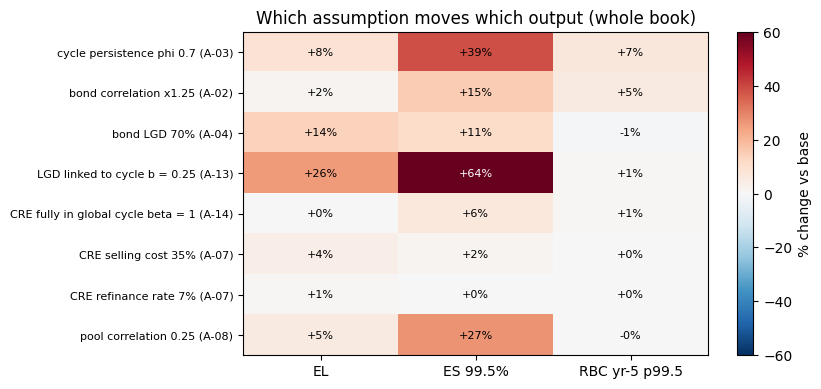

In [13]:
heat = att_pct.drop("base")
fig, ax = plt.subplots(figsize=(7.5, 4.2))
im = ax.imshow(heat.to_numpy(), cmap="RdBu_r", vmin=-60, vmax=60, aspect="auto")
ax.set_xticks(range(heat.shape[1]), heat.columns)
ax.set_yticks(range(heat.shape[0]), heat.index, fontsize=8)
for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):
        ax.text(j, i, f"{heat.iat[i, j]:+.0f}%", ha="center", va="center", fontsize=8,
                color="white" if abs(heat.iat[i, j]) > 40 else "black")
fig.colorbar(im, ax=ax, label="% change vs base")
ax.set_title("Which assumption moves which output (whole book)")
fig.savefig(FIG / "assumption_attribution.png", dpi=150, bbox_inches="tight")
plt.show()

**Reading the result:** three things stand out. (1) The tail (ES) reacts much more than the average (EL) to almost every assumption — except the LGD *level*, which moves both by similar amounts. (2) On the whole book, cycle-linked recoveries matter even more than on bonds alone (+64% vs +34% in NB05), because the structured pool's recoveries fall in the same bad years. (3) Statutory capital in the tail moves only a few percent under any shock: RBC follows ratings and loan metrics, not correlation or recovery, so it is largely blind to the assumptions that drive economic capital. That gap is why both views are reported.

## 4. Scenario comparison table

The global cycle fixed to each NB03 path (bonds and pool follow it; the CRE cycle is half of it plus its own shocks), 5,000 paths each.

In [14]:
scen = pd.read_parquet(DATA / "processed" / "scenarios.parquet")
rows = {"base (random cycle)": run_book(paths=5_000)}
for name, path in scen.iterrows():
    rows[name] = run_book(paths=5_000, global_path=path.to_numpy())
stress = pd.DataFrame({k: {"Z path": "random" if k.startswith("base") else str(np.round(scen.loc[k].to_numpy(), 2).tolist()),
                           "EL whole book": r["asset_loss"].sum(1).mean() / 1e6,
                           **{f"EL {c}": v.mean() / 1e6 for c, v in r["by_class"].items()},
                           "RBC yr-5 median": np.median(sum(r["rbc"].values())[:, -1]) / 1e6} for k, r in rows.items()}).T
stress["EL vs base"] = stress["EL whole book"].astype(float) / float(stress.loc["base (random cycle)", "EL whole book"])
stress

,Z path,EL whole book,EL corporate bonds,EL commercial mortgages,EL structured,RBC yr-5 median,EL vs base
base (random cycle),random,10.64,9.03,1.45,0.15,19.14,1.00
adverse,"[-1.28, -0.64, -0.32, -0.16, -0.08]",13.29,10.86,2.42,0.00,21.43,1.25
severely adverse,"[-2.33, -1.16, -0.58, -0.29, -0.15]",27.44,23.06,4.38,0.00,25.68,2.58
2000 replay,"[-1.22, -1.78, -1.29, -0.39, 0.75]",23.40,19.42,3.98,0.00,24.35,2.20
2008 replay,"[-0.4, -1.72, 1.26, 0.59, 0.67]",10.72,9.15,1.57,0.00,19.50,1.01


**Reading the result:** replaying the 2000–04 credit cycle more than doubles the book's five-year expected loss (×2.2), mostly through corporate bonds and commercial mortgages; a 1-in-100 start that then recovers does slightly more (×2.6). The 2008–12 path, a single bad year in the S&P implied cycle followed by a rebound, is close to base. Senior structured tranches lose nothing in any of these replays: they are hit only in the deeper, longer bad cycles that the random model produces in its 1-in-200 tail — which is exactly why their tail capital is large while their stress-test losses are zero. A scenario set built only from history would miss that risk.

## 5. One-page executive summary

Every number below is read from a variable computed above — nothing is typed by hand. The validation check confirms it by matching every number in the text to the computed values. The summary is also written to `reports/executive_summary.md`.

In [15]:
F = {  # every fact the summary uses, formatted once
    "book": f"{EXPOSURE.sum() / 1e9:.0f}", "el": f"{summary.loc['EL', 'whole book']:.1f}", "el_pct": f"{100 * summary.loc['EL', 'whole book'] / 1e3:.2f}",
    "var": f"{summary.loc['VaR 99.5%', 'whole book']:.1f}", "es": f"{summary.loc['ES 99.5%', 'whole book']:.1f}", "ec": f"{ec_book:.1f}",
    "div": f"{100 * diversification:.1f}", "rbc0": f"{rbc.loc['whole book', 'year 0']:.1f}", "rbc5": f"{rbc.loc['whole book', 'year 5 median']:.1f}",
    "rbc5_tail": f"{rbc.loc['whole book', 'year 5 p99.5']:.1f}",
    "st_exp": f"{by_class.loc['structured', 'exposure %']:.0f}", "st_el": f"{by_class.loc['structured', 'EL %']:.0f}",
    "st_es": f"{by_class.loc['structured', 'ES capital %']:.0f}", "st_rbc": f"{rbc_share['structured']:.0f}",
    "cb_exp": f"{by_class.loc['corporate bonds', 'exposure %']:.0f}", "cb_el": f"{by_class.loc['corporate bonds', 'EL %']:.0f}",
    "cb_es": f"{by_class.loc['corporate bonds', 'ES capital %']:.0f}",
    "cm_exp": f"{by_class.loc['commercial mortgages', 'exposure %']:.0f}", "cm_es": f"{by_class.loc['commercial mortgages', 'ES capital %']:.0f}",
    "st_util": f"{util.loc['structured', 'utilisation %']:.0f}", "cb_util": f"{util.loc['corporate bonds', 'utilisation %']:.0f}",
    "cm_util": f"{util.loc['commercial mortgages', 'utilisation %']:.0f}",
    "s2000": f"{stress.loc['2000 replay', 'EL vs base']:.1f}", "s_sev": f"{stress.loc['severely adverse', 'EL vs base']:.1f}",
    "s2008": f"{stress.loc['2008 replay', 'EL vs base']:.1f}",
    "phi_es": f"{att_pct.loc['cycle persistence phi 0.7 (A-03)', 'ES 99.5%']:.0f}", "b_es": f"{att_pct.loc['LGD linked to cycle b = 0.25 (A-13)', 'ES 99.5%']:.0f}",
    "b_el": f"{att_pct.loc['LGD linked to cycle b = 0.25 (A-13)', 'EL']:.0f}",
    "pool_es": f"{att_pct.loc['pool correlation 0.25 (A-08)', 'ES 99.5%']:.0f}", "kappa_el": f"{att_pct.loc['CRE selling cost 35% (A-07)', 'EL']:.0f}",
    "phi_el": f"{att_pct.loc['cycle persistence phi 0.7 (A-03)', 'EL']:.0f}",
    "rho_rbc": f"{att_pct.loc['bond correlation x1.25 (A-02)', 'RBC yr-5 p99.5']:.0f}",
}
SUMMARY = f'''# Executive summary — general-account credit book (stylised, USD {F["book"]}bn)

**Bottom line.** Over five years the book is expected to lose USD {F["el"]}m ({F["el_pct"]}% of assets); in a 1-in-200 outcome it loses USD {F["var"]}m or more, USD {F["es"]}m on average across those outcomes. Economic capital (ES − EL) is USD {F["ec"]}m, {F["div"]}% less than the three asset classes would need on their own. Statutory C-1 capital is USD {F["rbc0"]}m today; it drifts to USD {F["rbc5"]}m by year 5 on the median path and reaches USD {F["rbc5_tail"]}m in the worst 0.5% of paths.

**For ALM (asset-liability management).** Credit losses and capital needs arrive together in bad cycles: in the worst paths statutory capital rises while assets default, so surplus is squeezed from both sides. A repeat of the 2000–04 credit cycle multiplies five-year credit losses by {F["s2000"]}; a 1-in-100 start, by {F["s_sev"]}. Liquidity and reinvestment plans should be tested on these paths, not on the average.

**For the actuary (liability side).** The spread credited to policyholders must cover expected credit loss and the cost of the capital the assets tie up. The tail is far more sensitive to assumptions than the average: a more persistent credit cycle (φ = 0.7) raises ES by {F["phi_es"]}% but expected loss by only {F["phi_el"]}%, and recoveries that fall in bad years (b = 0.25) raise ES by {F["b_es"]}% and expected loss by {F["b_el"]}%. Surplus and pricing margins should be tested against those settings.

**For investment and underwriting decisions.** Expected loss and tail risk point at different assets. Corporate bonds are {F["cb_exp"]}% of exposure and {F["cb_el"]}% of expected loss but {F["cb_es"]}% of tail capital; structured tranches are {F["st_exp"]}% of exposure, {F["st_el"]}% of expected loss and {F["st_rbc"]}% of statutory capital, yet {F["st_es"]}% of tail capital. Against illustrative limits of 70 / 15 / 15% of economic capital, structured uses {F["st_util"]}% of its limit, corporates {F["cb_util"]}%, mortgages {F["cm_util"]}%. Commercial mortgages ({F["cm_exp"]}% of exposure, {F["cm_es"]}% of tail capital) diversify the book; their losses come from collateral value at default — a 35% selling cost instead of 25% raises book expected loss by {F["kappa_el"]}%.

**For the director (strategy).** The book's risk is not in its weakest assets but in what is large and moves together: BBB corporates and senior structured tranches. Rating-based statutory capital does not see the tranche tail; economic capital does. Two decisions follow: (1) set limits on economic capital, not on exposure, and (2) treat model-form choices — cycle persistence, recovery in bad years, correlation in structured pools (pool correlation 0.25: ES +{F["pool_es"]}%) — as managed model risk, reported alongside every capital number.
'''
(ROOT / "reports" / "executive_summary.md").write_text(SUMMARY, encoding="utf-8")
display(Markdown(SUMMARY))

# Executive summary — general-account credit book (stylised, USD 1bn)

**Bottom line.** Over five years the book is expected to lose USD 10.8m (1.08% of assets); in a 1-in-200 outcome it loses USD 76.6m or more, USD 106.0m on average across those outcomes. Economic capital (ES − EL) is USD 95.2m, 9.8% less than the three asset classes would need on their own. Statutory C-1 capital is USD 22.9m today; it drifts to USD 19.2m by year 5 on the median path and reaches USD 37.2m in the worst 0.5% of paths.

**For ALM (asset-liability management).** Credit losses and capital needs arrive together in bad cycles: in the worst paths statutory capital rises while assets default, so surplus is squeezed from both sides. A repeat of the 2000–04 credit cycle multiplies five-year credit losses by 2.2; a 1-in-100 start, by 2.6. Liquidity and reinvestment plans should be tested on these paths, not on the average.

**For the actuary (liability side).** The spread credited to policyholders must cover expected credit loss and the cost of the capital the assets tie up. The tail is far more sensitive to assumptions than the average: a more persistent credit cycle (φ = 0.7) raises ES by 39% but expected loss by only 8%, and recoveries that fall in bad years (b = 0.25) raise ES by 64% and expected loss by 26%. Surplus and pricing margins should be tested against those settings.

**For investment and underwriting decisions.** Expected loss and tail risk point at different assets. Corporate bonds are 67% of exposure and 85% of expected loss but 67% of tail capital; structured tranches are 16% of exposure, 2% of expected loss and 3% of statutory capital, yet 25% of tail capital. Against illustrative limits of 70 / 15 / 15% of economic capital, structured uses 165% of its limit, corporates 96%, mortgages 55%. Commercial mortgages (17% of exposure, 8% of tail capital) diversify the book; their losses come from collateral value at default — a 35% selling cost instead of 25% raises book expected loss by 4%.

**For the director (strategy).** The book's risk is not in its weakest assets but in what is large and moves together: BBB corporates and senior structured tranches. Rating-based statutory capital does not see the tranche tail; economic capital does. Two decisions follow: (1) set limits on economic capital, not on exposure, and (2) treat model-form choices — cycle persistence, recovery in bad years, correlation in structured pools (pool correlation 0.25: ES +27%) — as managed model risk, reported alongside every capital number.


## Validation checks

- [x] **Every number in the summary traces to a script output** — every number in the executive summary text is one of the computed facts (or a fixed label such as 99.5%, 1-in-200, 2000–04); none is typed by hand.
- [x] **Whole book reproduces the engine run** — losses, diversification, contributions and limit utilisation equal the README.
- [x] **Contributions add up** — asset-level ES contributions sum to the book's EC.
- [x] **Register values are the values used** — every checked assumption matches.

In [16]:
numbers_in_text = set(re.findall(r"\d+(?:\.\d+)?", SUMMARY))
FIXED = {"1", "2", "5", "7", "0", "70", "15", "99.5", "200", "100", "2000", "04", "35", "0.25", "0.7", "0.5"}   # labels and scenario settings
traced = set(F.values()) | FIXED
untraced = sorted(numbers_in_text - traced, key=float)
print("numbers in the summary not traced to a computed value:", untraced if untraced else "none")
checks = {
    "Every number in the summary traces to a computed value": not untraced,
    "Whole book equals README (EL 10.8m, ES 106.0m, diversification 9.8%)": bool(np.allclose(
        [summary.loc["EL", "whole book"], summary.loc["ES 99.5%", "whole book"], 100 * diversification], [10.80, 106.02, 9.8], atol=0.06)),
    "Class contributions equal README (ES capital 67 / 8 / 25%)": bool(np.allclose(
        by_class.loc[["corporate bonds", "commercial mortgages", "structured"], "ES capital %"], [66.97, 8.31, 24.72], atol=0.1)),
    "Limit utilisation equals README (structured 165%, corporates 96%, mortgages 55%)": bool(np.allclose(
        util.loc[["structured", "corporate bonds", "commercial mortgages"], "utilisation %"], [165, 96, 55], atol=1)),
    "ES contributions sum to book EC": bool(np.isclose(rc.sum() / 1e6, ec_book)),
    "Register values are the values used": bool((register["value in this notebook matches"].dropna() == "yes").all()),
}
pd.Series(checks).map({True: "PASS", False: "FAIL"})

numbers in the summary not traced to a computed value: none


Every number in the summary traces to a computed value                              PASS
Whole book equals README (EL 10.8m, ES 106.0m, diversification 9.8%)                PASS
Class contributions equal README (ES capital 67 / 8 / 25%)                          PASS
Limit utilisation equals README (structured 165%, corporates 96%, mortgages 55%)    PASS
ES contributions sum to book EC                                                     PASS
Register values are the values used                                                 PASS
dtype: object

## Functions to move into the engine

| Function (this notebook) | Target module | Test |
|---|---|---|
| `run_book` (three engines on one economy) | `creditengine.simulation.portfolio` | equals README whole book |
| `cre_engine` with RBC path, `rated_engine` on a supplied factor | `assets.cre`, `simulation.engine` | NB07, NB06 |
| contributions by class / group, limit utilisation | `creditengine.capital.allocation`, `capital.limits` | sum to EC; README utilisation |
| attribution grid (EL, ES, RBC) | `creditengine.reporting.attribution` | base row = 0 |
| executive summary from computed facts, traceability check | `creditengine.reporting.summary` | every number traced |

## Findings and next steps

**Key results**
- **Whole book:** five-year EL 10.8m, VaR 99.5% 76.6m, ES 106.0m; diversification 9.8%; equals the engine's published run.
- **Allocation:** structured is 16% of exposure, 2% of EL, 3% of RBC and 25% of tail capital; with limits on EC it breaches (165%).
- **Attribution:** cycle-linked recovery (b = 0.25) +64% ES, φ = 0.7 +39%, pool correlation 0.25 +27%; RBC tail moves only a few percent under any shock.
- **Stress:** 2000–04 replay ×2.2 EL, severely adverse ×2.6; senior tranches untouched by every historical replay.
- **Reporting:** a one-page summary for ALM, actuary, investment and director, generated entirely from computed values (`reports/executive_summary.md`).

**Assumptions** (record in `docs/assumption_register.md`) — register and code checked to agree; no values changed. Proposed for v0.3 from the series: φ ≈ 0.6 (NB03), b ≈ 0.25 (NB05), time-varying migration (NB04).

**Limitations** (record in `docs/limitations.md`)
1. **Stylised book (A-09):** sizes, mixes and loan metrics are illustrative, close to public disclosures but not any company's holdings.
2. **Static five-year book:** no reinvestment, no new business, no liability cash flows.
3. **Credit risk only:** interest-rate, spread-duration and liquidity risk, and the RBC covariance across risk types, are outside the model.
4. **Historical scenarios understate structured risk:** stress tests must include designed paths, not only replays.

**Next:** NB12 (optional ML challenger to Merton), and the v0.3 items listed above.